# L2 - Classification with XGBoost (Ames Housing)

Goal: predict the price range of a house with an XGBoost multiclass classifier. The 6 classes are:

| class | price |
|---|---|
| 0 | < 100,000 |
| 1 | 100,000 - 130,000 |
| 2 | 130,000 - 180,000 |
| 3 | 180,000 - 250,000 |
| 4 | 250,000 - 400,000 |
| 5 | >= 400,000 |

We mostly look at macro-F1, since that's the metric used for the ranking and it treats all classes equally.

## 1. Setup

In [1]:
# !pip install xgboost plotly optuna anywidget
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

SEED = 42
CLASS_NAMES = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]
print("xgboost", xgb.__version__)

xgboost 3.4.1


In [2]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

## 2. Data

### 2.1 Cleaning (same as Aufgabe 1)
This is our cleaning function from L1. It fills the NaNs that just mean "house doesn't have it",
fixes some inconsistent rows, drops the 3 outliers (huge houses sold as "Partial") and adds the extra
features (Total SF, Total Bath, House Age, Has Pool, Has Garage).

One change compared to L1: we no longer impute Lot Frontage (median per neighborhood) and Electrical (mode).
Those medians were computed on the whole dataset, so the test houses influenced the values used for training,
which is a small data leak. Since XGBoost works with missing values anyway, we just leave them as NaN.
Everything else in `clean` only looks at the row itself, so it can stay before the split.

In [3]:
def load_raw(path="AmesHousing.csv"):
    """Read the original data (tab-separated)."""
    return pd.read_csv(path, sep="\t")


def clean(housing):
    """Return the cleaned Ames Housing data (2927 rows, 85 columns)."""
    df = housing.copy()

    # NaN = the house doesn't have the feature
    none_cat = ["Alley", "Fence", "Misc Feature", "Pool QC", "Fireplace Qu", "Mas Vnr Type",
                "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
                "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
    zero_num = ["Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
                "Bsmt Full Bath", "Bsmt Half Bath", "Garage Area", "Garage Cars"]
    df[none_cat] = df[none_cat].fillna("None")
    df[zero_num] = df[zero_num].fillna(0)

    # real missing data (Lot Frontage, 1x Electrical): left as NaN on purpose.
    # In L1 we filled them with the median/mode of the whole dataset, but that uses the test rows too
    # (small leakage). XGBoost can handle NaN directly, so we don't need to impute here.

    # rows that contradict themselves: most common value
    has_bsmt = df["Bsmt Qual"] != "None"
    df.loc[has_bsmt & (df["Bsmt Exposure"] == "None"), "Bsmt Exposure"] = "No"
    df.loc[(df["BsmtFin SF 2"] > 0) & (df["BsmtFin Type 2"] == "None"), "BsmtFin Type 2"] = "Rec"

    # veneer type "None" but area > 0: trust the type
    df.loc[(df["Mas Vnr Type"] == "None") & (df["Mas Vnr Area"] > 0), "Mas Vnr Area"] = 0

    # garage type set, but every other garage column is empty: no garage
    df.loc[(df["Garage Type"] != "None") & (df["Garage Area"] == 0), "Garage Type"] = "None"
    # real garage without details: most common values for detached garages
    no_info = (df["Garage Type"] != "None") & (df["Garage Finish"] == "None")
    df.loc[no_info, ["Garage Finish", "Garage Qual", "Garage Cond"]] = ["Unf", "TA", "TA"]

    # typo in Garage Yr Blt (2207)
    bad = df["Garage Yr Blt"] > 2010
    df.loc[bad, "Garage Yr Blt"] = df.loc[bad, "Year Built"]

    # MS SubClass is a code, not a number
    df["MS SubClass"] = df["MS SubClass"].astype(str)

    # outliers: huge houses sold as unfinished ("Partial") for far too little
    outliers = (df["Gr Liv Area"] > 4000) & (df["Sale Condition"] == "Partial")
    df = df[~outliers].copy()

    # new features
    df["Total SF"] = df["Gr Liv Area"] + df["Total Bsmt SF"]
    df["Total Bath"] = (df["Full Bath"] + 0.5 * df["Half Bath"]
                        + df["Bsmt Full Bath"] + 0.5 * df["Bsmt Half Bath"])
    df["House Age"] = df["Yr Sold"] - df["Year Built"]
    df["Has Pool"] = (df["Pool Area"] > 0).astype(int)
    df["Has Garage"] = (df["Garage Area"] > 0).astype(int)

    return df.drop(columns=["Order", "PID"])


df = clean(load_raw("AmesHousing.csv"))
df.shape

(2927, 85)

### 2.2 Target: 6 price classes
We use `pd.cut` with `right=False`, so the bins are closed on the left. A house sold for exactly 100,000
goes into 100-130k and one for exactly 400,000 goes into ">=400k", which matches the task.

,class,n,%
0,<100k,237,8.1
1,100-130k,509,17.4
2,130-180k,1036,35.4
3,180-250k,684,23.4
4,250-400k,397,13.6
5,>=400k,64,2.2


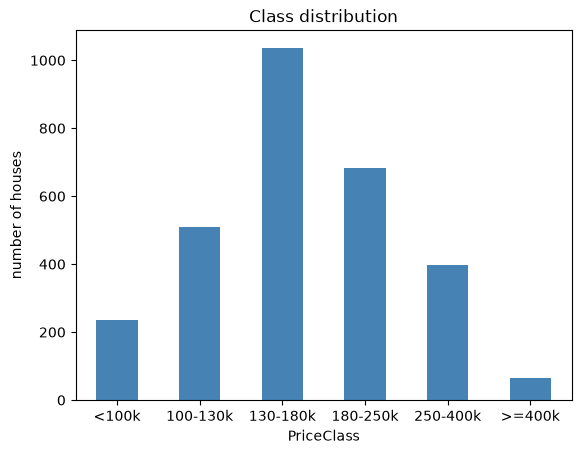

In [4]:
BINS = [-np.inf, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
df["PriceClass"] = pd.cut(df["SalePrice"], bins=BINS, right=False, labels=False).astype(int)

counts = df["PriceClass"].value_counts().sort_index()
display(pd.DataFrame({"class": CLASS_NAMES, "n": counts.values,
                      "%": (100 * counts / counts.sum()).round(1).values}))

ax = counts.plot.bar(color="steelblue")
ax.set_xticklabels(CLASS_NAMES, rotation=0)
ax.set_title("Class distribution"); ax.set_ylabel("number of houses")
plt.show()

The classes are quite imbalanced. 130-180k has about 35% of the houses, while >=400k has only 64 houses (2.2%).
So accuracy alone isn't very useful here, and a 10% test set would only contain about 6 houses from the
last class. That's why stratification matters, we check it below.

### 2.3 Encoding the categorical features

- Ordinal columns (marked "Ordinal" in AmesExplanations.txt, e.g. quality Po < Fa < TA < Gd < Ex) are mapped
  to integers in their natural order. "None" (feature doesn't exist) gets 0.
- Nominal columns (Neighborhood, Roof Style, ...) are one-hot encoded.

SalePrice and PriceClass are removed from X, otherwise the model would just read the answer.

We don't call `add_quality_scores` from L1 anymore, because the ordinal encoding already replaces those
quality columns with numbers (we would get duplicate columns otherwise).

In [5]:
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {
    "Lot Shape":      {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Utilities":      {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Land Slope":     {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Exter Qual": QUAL, "Exter Cond": QUAL, "Bsmt Qual": QUAL, "Bsmt Cond": QUAL,
    "Heating QC": QUAL, "Kitchen Qual": QUAL, "Fireplace Qu": QUAL,
    "Garage Qual": QUAL, "Garage Cond": QUAL, "Pool QC": QUAL,
    "Bsmt Exposure":  {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Electrical":     {"Mix": 0, "FuseP": 1, "FuseF": 2, "FuseA": 3, "SBrkr": 4},
    "Functional":     {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Garage Finish":  {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Paved Drive":    {"N": 0, "P": 1, "Y": 2},
    "Fence":          {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}
TARGET_COLS = ["SalePrice", "PriceClass"]


def encode_ordinal_onehot(data):
    X = data.drop(columns=TARGET_COLS).copy()
    for col, mapping in ORDINAL_MAPS.items():
        missing = set(X[col].dropna().unique()) - set(mapping)
        assert not missing, f"no mapping for {col}: {missing}"   # check we didn't forget a value
        X[col] = X[col].map(mapping)
    nominal = X.select_dtypes(exclude="number").columns
    X = pd.get_dummies(X, columns=nominal, dtype=int)
    # xgboost doesn't accept [, ] or < in feature names
    X.columns = [c.replace("[", "(").replace("]", ")").replace("<", "lt") for c in X.columns]
    return X


X = encode_ordinal_onehot(df)
y = df["PriceClass"].to_numpy()
print("X shape:", X.shape)
print("NaNs left:", X.isna().sum()[X.isna().sum() > 0].to_dict())

X shape: (2927, 249)
NaNs left: {'Lot Frontage': 490, 'Electrical': 1, 'Garage Yr Blt': 159}


The NaNs left are Lot Frontage (not given for ~490 houses), Garage Yr Blt (houses without a garage) and one
Electrical value. We leave them, XGBoost handles missing values itself: at each split it learns which side
the NaNs should go to.

Doing the one-hot encoding before the train/test split is fine, `get_dummies` doesn't learn anything
from the data distribution, it just creates 0/1 columns.

## 3. Baseline XGBoost

We use `XGBClassifier` with `objective="multi:softprob"`. For multiclass, XGBoost builds one tree per class
in every boosting round, so 200 rounds give 6 x 200 = 1200 trees. The 6 tree outputs are put through
softmax to get class probabilities, and the predicted class is the one with the highest probability.

For the baseline we keep almost everything default (only `n_estimators=200` and `learning_rate=0.1` are set).

In [6]:
BASE_PARAMS = dict(
    objective="multi:softprob",
    num_class=6,
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1,
)


def make_model(**params):
    return xgb.XGBClassifier(**{**BASE_PARAMS, **params})


def scores(model, X_tr, y_tr, X_te, y_te):
    # also return train F1 so we can see how much the model overfits
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    return {
        "train_macro_f1": f1_score(y_tr, p_tr, average="macro"),
        "test_macro_f1": f1_score(y_te, p_te, average="macro"),
        "test_accuracy": accuracy_score(y_te, p_te),
    }

## 4. Train/test split, stratification and k-fold CV

### 4.1 Split 10% vs 20%, with and without stratification
The result of one split depends a lot on which houses end up in the test set, so we repeat every
configuration with 10 different random seeds and look at mean and std.

In [7]:
SEEDS = range(10)
rows, n_top_class = [], {}

for test_size in [0.10, 0.20]:
    for stratify in [False, True]:
        name = f"{int(test_size*100)}% {'stratified' if stratify else 'not stratified'}"
        n_top_class[name] = []
        for s in SEEDS:
            X_tr, X_te, y_tr, y_te = train_test_split(
                X, y, test_size=test_size, random_state=s, stratify=y if stratify else None)
            model = make_model().fit(X_tr, y_tr)
            rows.append({"config": name, "seed": s, **scores(model, X_tr, y_tr, X_te, y_te)})
            n_top_class[name].append(int((y_te == 5).sum()))

split_res = pd.DataFrame(rows)
split_summary = split_res.drop(columns="seed").groupby("config", sort=False).agg(["mean", "std"]).round(4)
split_summary[">=400k in test (min-max)"] = [f"{min(v)}-{max(v)}" for v in n_top_class.values()]
split_summary

train_macro_f1      test_macro_f1         test_accuracy  \
                             mean  std          mean     std          mean   
config                                                                       
10% not stratified            1.0  0.0        0.7456  0.0301        0.7498   
10% stratified                1.0  0.0        0.7689  0.0270        0.7703   
20% not stratified            1.0  0.0        0.7466  0.0175        0.7618   
20% stratified                1.0  0.0        0.7575  0.0209        0.7643   

                           >=400k in test (min-max)  
                       std                           
config                                               
10% not stratified  0.0281                      4-9  
10% stratified      0.0240                      6-6  
20% not stratified  0.0138                    10-17  
20% stratified      0.0189                    13-13

**What the table shows:**

- Train macro-F1 is 1.0 in every run, test is only ~0.75-0.77.
- 10% vs 20%: the mean test F1 is about the same, but the std is lower with 20% (~0.02 vs ~0.03). With 10% there are only ~6 houses >=400k in the test set, so one wrong prediction changes macro-F1 a lot. The 20% split gives a more reliable estimate.
- Stratification: without it, the number of >=400k houses in the test set changes from split to split (4-9 and 10-17), with it it's always the same (6 and 13). The stratified splits also score higher on average (0.769 vs 0.746 for 10%, 0.758 vs 0.747 for 20%). The std isn't lower everywhere, so with 10 seeds we can't say it's more stable, but it keeps the class mix the same in every test set, which makes results comparable.
- Accuracy is a bit higher than macro-F1 because it's dominated by the big classes (130-180k is 35% of the data), while macro-F1 is pulled down by the small classes, mainly >=400k.

So for the next experiments we use a stratified 20% test set.

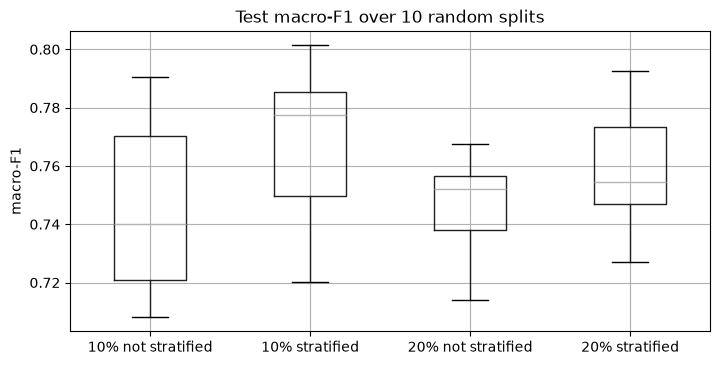

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
split_res.boxplot(column="test_macro_f1", by="config", ax=ax)
ax.set_title("Test macro-F1 over 10 random splits"); ax.set_xlabel(""); ax.set_ylabel("macro-F1")
plt.suptitle(""); plt.show()

### 4.2 K-fold CV: k=5 vs k=10, KFold vs StratifiedKFold

In [9]:
def run_cv(X, y, cv, model_fn=make_model):
    out = []
    for fold, (tr, va) in enumerate(cv.split(X, y)):
        m = model_fn().fit(X.iloc[tr], y[tr])
        out.append({"fold": fold, **scores(m, X.iloc[tr], y[tr], X.iloc[va], y[va]),
                    "n_>=400k_val": int((y[va] == 5).sum())})
    return pd.DataFrame(out)


cv_results, cv_rows = {}, []
for k in [5, 10]:
    for cv_name, cv in [("KFold", KFold(k, shuffle=True, random_state=SEED)),
                        ("StratifiedKFold", StratifiedKFold(k, shuffle=True, random_state=SEED))]:
        name = f"k={k} {cv_name}"
        r = run_cv(X, y, cv)
        cv_results[name] = r
        cv_rows.append({
            "config": name,
            "train_macro_f1": r.train_macro_f1.mean(),
            "val_macro_f1_mean": r.test_macro_f1.mean(),
            "val_macro_f1_std": r.test_macro_f1.std(),
            "val_accuracy_mean": r.test_accuracy.mean(),
            ">=400k per fold (min-max)": f"{r['n_>=400k_val'].min()}-{r['n_>=400k_val'].max()}",
        })

cv_summary = pd.DataFrame(cv_rows).set_index("config").round(4)
cv_summary

,train_macro_f1,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,>=400k per fold (min-max)
config,,,,,
k=5 KFold,1.0,0.7456,0.0175,0.7591,9-22
k=5 StratifiedKFold,1.0,0.7555,0.0153,0.7666,12-13
k=10 KFold,1.0,0.7516,0.0204,0.7591,4-12
k=10 StratifiedKFold,1.0,0.7573,0.0415,0.7680,6-7


**K-fold results:**

- StratifiedKFold is slightly better than KFold for both k (0.756 vs 0.746 for k=5, 0.757 vs 0.752 for k=10). The last column shows why: with KFold(5) one fold had only 9 houses >=400k and another 22, with StratifiedKFold every fold has 12-13. A fold with very few expensive houses gets a bad F1 for that class.
- k=5 vs k=10: the mean is almost the same, so training on 90% instead of 80% of the data doesn't help here. The std goes up with k=10 (up to 0.042 for StratifiedKFold), because each validation fold is only ~293 houses with 6-7 expensive ones, so every fold score is noisier. The per-fold table shows two folds (0.688 and 0.698) that pull the std up. k=10 also takes twice as long.
- This is the bias-variance tradeoff: bigger k means less bias (more training data per model) but more variance in the fold scores.

We use StratifiedKFold with k=5 for the rest of the lab: same score, lowest std and faster.

In [10]:
# macro-F1 of every single fold
pd.DataFrame({name: r.test_macro_f1.round(3) for name, r in cv_results.items()})

,k=5 KFold,k=5 StratifiedKFold,k=10 KFold,k=10 StratifiedKFold
0,0.752,0.755,0.731,0.794
1,0.762,0.757,0.756,0.774
2,0.749,0.779,0.729,0.808
3,0.716,0.736,0.762,0.688
4,0.749,0.751,0.763,0.800
5,NaN,NaN,0.797,0.742
6,NaN,NaN,0.738,0.746
7,NaN,NaN,0.736,0.698
8,NaN,NaN,0.748,0.783
9,NaN,NaN,0.757,0.741


Interesting: for k=10 the stratified folds vary even more than the normal KFold ones. Stratification only fixes how many houses of each class are in a fold, not which ones, so a fold can still get more "hard" houses (e.g. prices close to a class border) and score lower.

In [11]:
# hold-out test set, not touched until the final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
CV5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

train: (2341, 249)  test: (586, 249)


From here on, all comparisons and tuning use 5-fold stratified CV on the training part only. The 20% test set is kept aside and used once at the end, so the final score isn't biased by our choices.

## 5. Looking inside the model: trees and feature importance

To find the "best" tree we need to know which boosting round was the best one. We split off 20% of the
training data as a validation set and train with early stopping: we allow up to 1000 rounds, but training
stops when the validation mlogloss hasn't improved for 50 rounds. `best_iteration` is the round with the
lowest validation loss.

best round: 118
val macro-F1: 0.7757


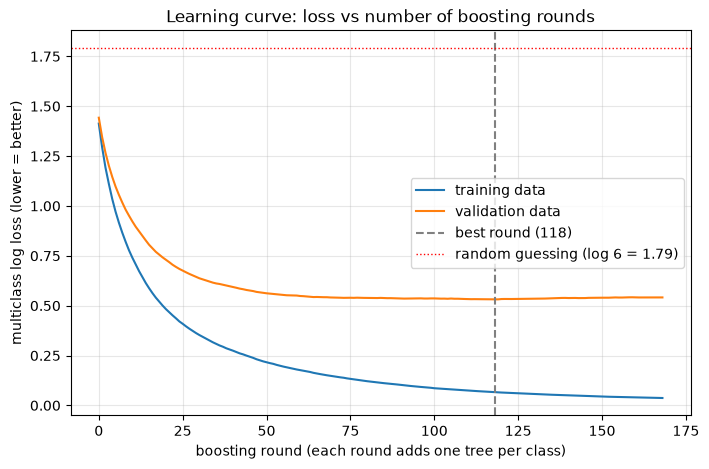

In [12]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train)

es_model = make_model(n_estimators=1000, early_stopping_rounds=50)
es_model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)

best_round = es_model.best_iteration
print("best round:", best_round)
print("val macro-F1:", round(f1_score(y_val, es_model.predict(X_val), average="macro"), 4))

hist = es_model.evals_result()
plt.figure(figsize=(8, 5))
plt.plot(hist["validation_0"]["mlogloss"], label="training data")
plt.plot(hist["validation_1"]["mlogloss"], label="validation data")
plt.axvline(best_round, color="gray", ls="--", label=f"best round ({best_round})")
plt.axhline(np.log(6), color="red", ls=":", lw=1, label="random guessing (log 6 = 1.79)")
plt.xlabel("boosting round (each round adds one tree per class)")
plt.ylabel("multiclass log loss (lower = better)")
plt.title("Learning curve: loss vs number of boosting rounds")
plt.legend(); plt.grid(alpha=.3)
plt.show()

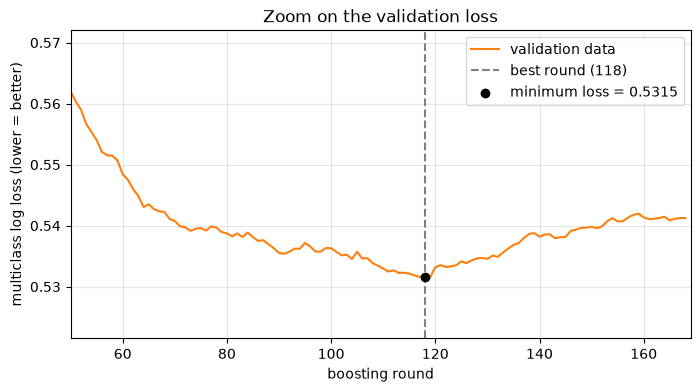

In [13]:
val_loss = hist["validation_1"]["mlogloss"]
plt.figure(figsize=(8, 4))
plt.plot(val_loss, color="tab:orange", label="validation data")
plt.axvline(best_round, color="gray", ls="--", label=f"best round ({best_round})")
plt.scatter(best_round, val_loss[best_round], color="black", zorder=3,
            label=f"minimum loss = {val_loss[best_round]:.4f}")
plt.xlim(50, len(val_loss))
plt.ylim(min(val_loss) - 0.01, val_loss[50] + 0.01)
plt.xlabel("boosting round"); plt.ylabel("multiclass log loss (lower = better)")
plt.title("Zoom on the validation loss")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 5.1 First and best tree

The value in each leaf is the score this tree adds for the class (before softmax), positive means
"more likely this class", negative "less likely".

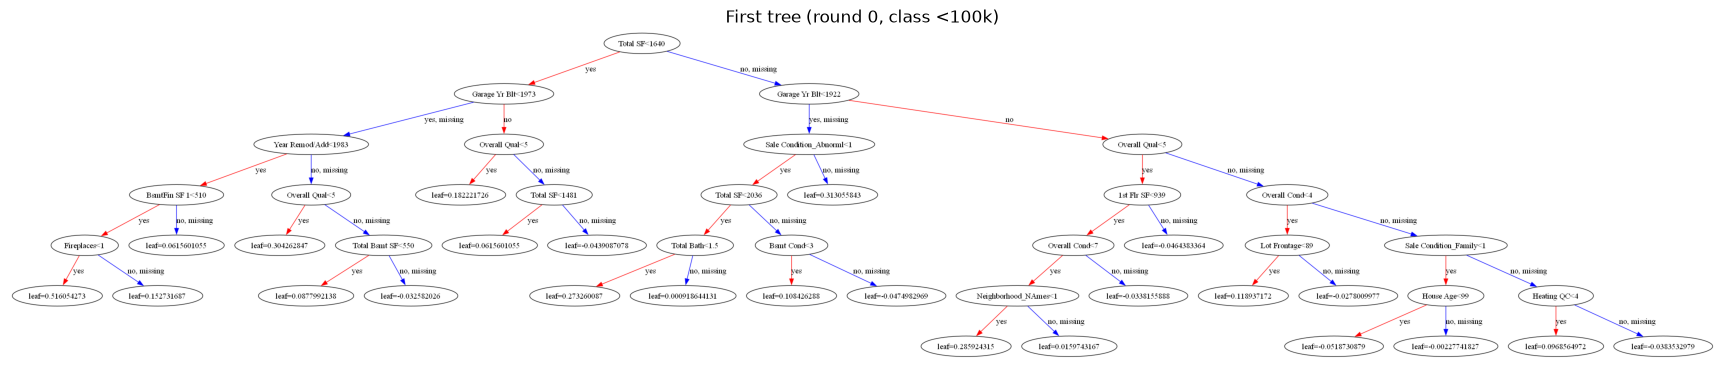

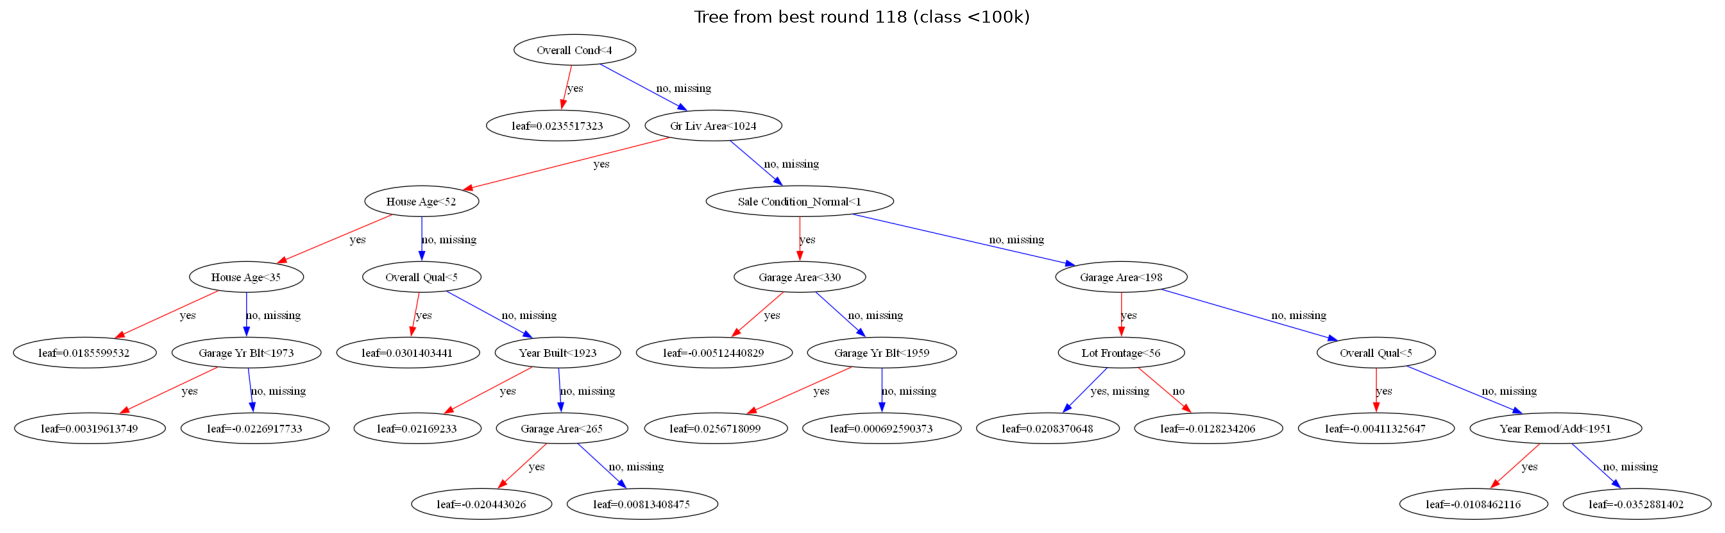

In [14]:
N_CLASSES = 6
first_idx = 0
best_idx = best_round * N_CLASSES + 0      # same class (<100k), best round

for idx, title in [(first_idx, "First tree (round 0, class <100k)"),
                   (best_idx, f"Tree from best round {best_round} (class <100k)")]:
    fig, ax = plt.subplots(figsize=(22, 9))
    xgb.plot_tree(es_model, tree_idx=idx, ax=ax)
    ax.set_title(title)
    plt.show()

In [15]:
# number of leaves, total gain and range of leaf values for both trees
trees = es_model.get_booster().trees_to_dataframe()
for idx in [first_idx, best_idx]:
    t = trees[trees.Tree == idx]
    print(f"tree {idx}: {(t.Feature == 'Leaf').sum()} leaves, total gain of splits = {t.loc[t.Feature != 'Leaf', 'Gain'].sum():.1f}")
    print("  leaf values between", round(t.loc[t.Feature == "Leaf", "Gain"].min(), 3),
          "and", round(t.loc[t.Feature == "Leaf", "Gain"].max(), 3))

tree 0: 24 leaves, total gain of splits = 538.0
  leaf values between -0.052 and 0.516
tree 708: 16 leaves, total gain of splits = 1.6
  leaf values between -0.035 and 0.03


The first tree splits first on Total SF and then on things like Overall Qual and the build/remodel years, the
obvious "big" features. Its leaf values go up to ~0.5 and the total gain of its splits is ~538, because at the
start the model knows nothing and every tree makes big corrections. The tree from round 118 starts with
Overall Cond and uses features like Sale Condition, Garage Area or Lot Frontage. Its leaf values are only
between -0.035 and 0.03 and the total gain is ~1.6, so it only fixes small leftover errors.


### 5.2 Feature importance: gain vs split (weight)

- **weight** (= split): how many times a feature is used for a split, over all trees
- **gain**: the average improvement of the loss when the feature is used for a split

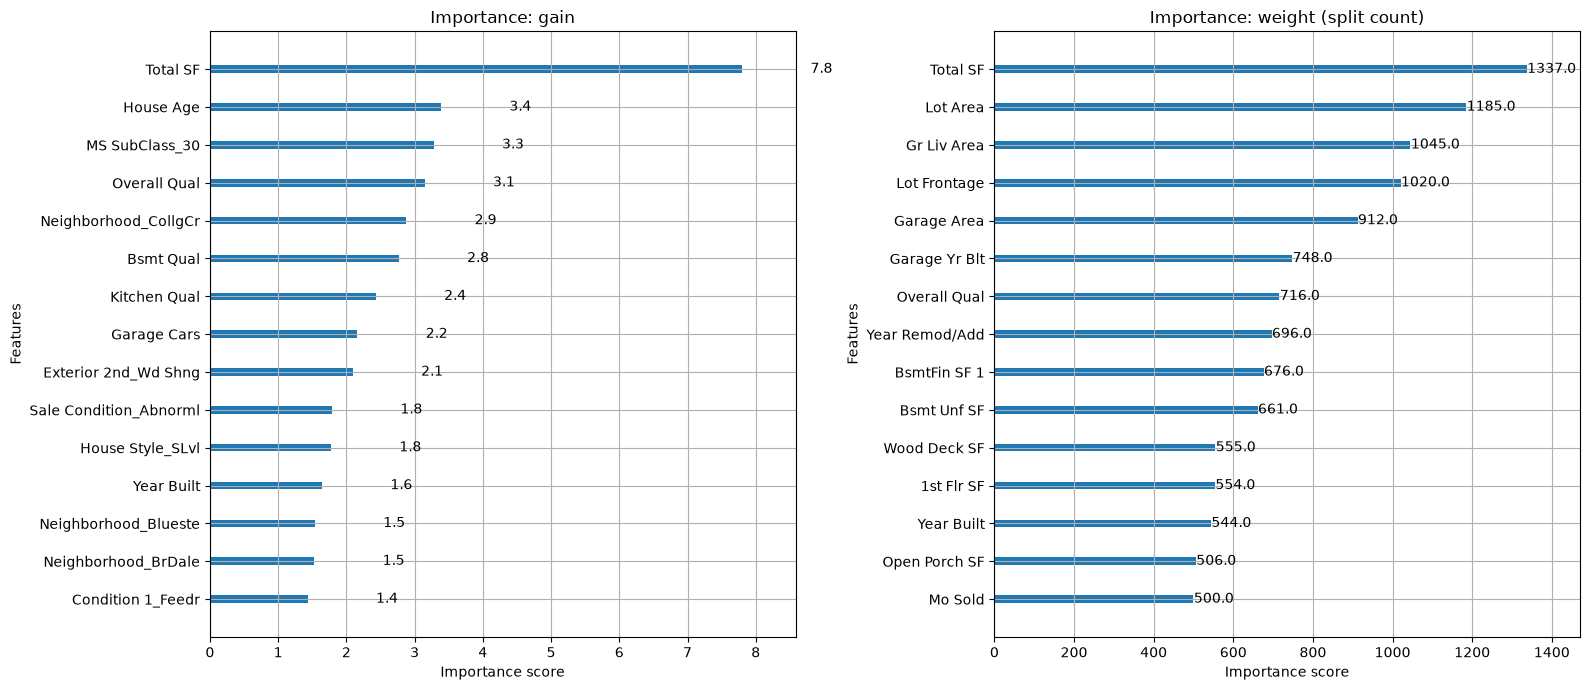

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
xgb.plot_importance(es_model, importance_type="gain", max_num_features=15, ax=axes[0],
                    title="Importance: gain", values_format="{v:.1f}")
xgb.plot_importance(es_model, importance_type="weight", max_num_features=15, ax=axes[1],
                    title="Importance: weight (split count)")
plt.tight_layout(); plt.show()

In [17]:
booster = es_model.get_booster()
imp = pd.DataFrame({"gain": pd.Series(booster.get_score(importance_type="gain")),
                    "weight": pd.Series(booster.get_score(importance_type="weight"))}).fillna(0)
imp["total_gain"] = pd.Series(booster.get_score(importance_type="total_gain"))
imp["gain_rank"] = imp.gain.rank(ascending=False).astype(int)
imp["weight_rank"] = imp.weight.rank(ascending=False).astype(int)
imp.sort_values("gain", ascending=False).head(15).round(2)

,gain,weight,total_gain,gain_rank,weight_rank
Total SF,7.80,1337.0,10432.26,1,1
House Age,3.39,462.0,1565.59,2,17
MS SubClass_30,3.28,16.0,52.49,3,109
Overall Qual,3.15,716.0,2253.83,4,7
Neighborhood_CollgCr,2.88,87.0,250.52,5,43
Bsmt Qual,2.77,152.0,420.88,6,29
Kitchen Qual,2.43,119.0,289.52,7,36
Garage Cars,2.16,63.0,136.26,8,51
Exterior 2nd_Wd Shng,2.10,3.0,6.29,9,142
Sale Condition_Abnorml,1.79,45.0,80.62,10,63


Total SF is first in both rankings, so the size of the house is clearly the most important feature.
After that the two rankings are quite different:

- By weight the top is full of continuous features (Lot Area, Gr Liv Area, Lot Frontage, Garage Area...).
  They have many possible split values, so the trees keep using them for small corrections, but each split
  gains little (Lot Area: 1185 splits, average gain 0.87).
- By gain we get House Age, Overall Qual, Bsmt Qual, Kitchen Qual, which are used less but separate cheap from
  expensive houses well.

So weight is biased towards continuous features with many values and average gain is noisy for rare features.
`total_gain` (gain x number of splits) is a good compromise: there the top is Total SF, Overall Qual,
House Age, which matches what we would expect for house prices.

## 6. Metrics, confusion matrix, ROC and PR curves

We still don't touch the test set. To get predictions for every training house from a model that didn't see
it, we use out-of-fold predictions: with `cross_val_predict` and our 5 stratified folds, every house is
predicted by the model trained on the other 4 folds. We put the evaluation in a function so we can use it
again for the final model on the test set.

In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

oof_proba = cross_val_predict(make_model(), X_train, y_train, cv=CV5, method="predict_proba")
oof_pred = oof_proba.argmax(axis=1)

In [19]:
def metric_table(y_true, y_pred):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "f1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "f1 (weighted)": f1_score(y_true, y_pred, average="weighted"),
    }).round(4)


def plot_confusion(y_true, y_pred, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASS_NAMES).plot(
        ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"{title} - counts")
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize="true"), display_labels=CLASS_NAMES).plot(
        ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f")
    axes[1].set_title(f"{title} - normalized per true class (= recall)")
    plt.tight_layout(); plt.show()


def plot_roc_pr(y_true, proba, title=""):
    Y = label_binarize(y_true, classes=range(N_CLASSES))
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for k, name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(Y[:, k], proba[:, k]):.3f})")
        prec, rec, _ = precision_recall_curve(Y[:, k], proba[:, k])
        axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(Y[:, k], proba[:, k]):.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title=f"{title} ROC (one-vs-rest)")
    axes[1].set(xlabel="Recall", ylabel="Precision", title=f"{title} Precision-Recall (one-vs-rest)")
    for ax in axes: ax.legend(loc="lower left" if ax is axes[1] else "lower right"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print("macro ROC-AUC:", round(roc_auc_score(y_true, proba, multi_class="ovr", average="macro"), 4))


display(metric_table(y_train, oof_pred).to_frame("baseline (OOF)"))
print(classification_report(y_train, oof_pred, target_names=CLASS_NAMES, digits=3))

,baseline (OOF)
accuracy,0.7475
precision (macro),0.7719
recall (macro),0.7354
f1 (macro),0.7520
f1 (weighted),0.7466


              precision    recall  f1-score   support

       <100k      0.772     0.658     0.710       190
    100-130k      0.637     0.607     0.621       407
    130-180k      0.751     0.809     0.779       829
    180-250k      0.760     0.759     0.759       547
    250-400k      0.824     0.795     0.809       317
      >=400k      0.889     0.784     0.833        51

    accuracy                          0.748      2341
   macro avg      0.772     0.735     0.752      2341
weighted avg      0.748     0.748     0.747      2341



- precision of a class: of the houses we predicted as this class, how many really are
- recall of a class: of the houses that really are in this class, how many we found
- f1: harmonic mean of the two; macro = simple average over the 6 classes

Macro-F1 of the baseline is 0.752 (accuracy 0.748). Surprisingly the rare >=400k class is not the problem,
it has the best F1 (0.83, precision 0.89): very expensive houses are quite different from the rest, so they
are easy to recognize. The weakest class is 100-130k (F1 0.62), followed by <100k (F1 0.71, recall only 0.66).
100-130k is a narrow range (only 30k wide) squeezed between two other classes, so it gets confused with both
neighbours. Precision (0.77) is higher than recall (0.74) on average, mainly because the small classes
(<100k, >=400k) are predicted carefully: when the model says ">=400k" it's usually right, but it misses some.

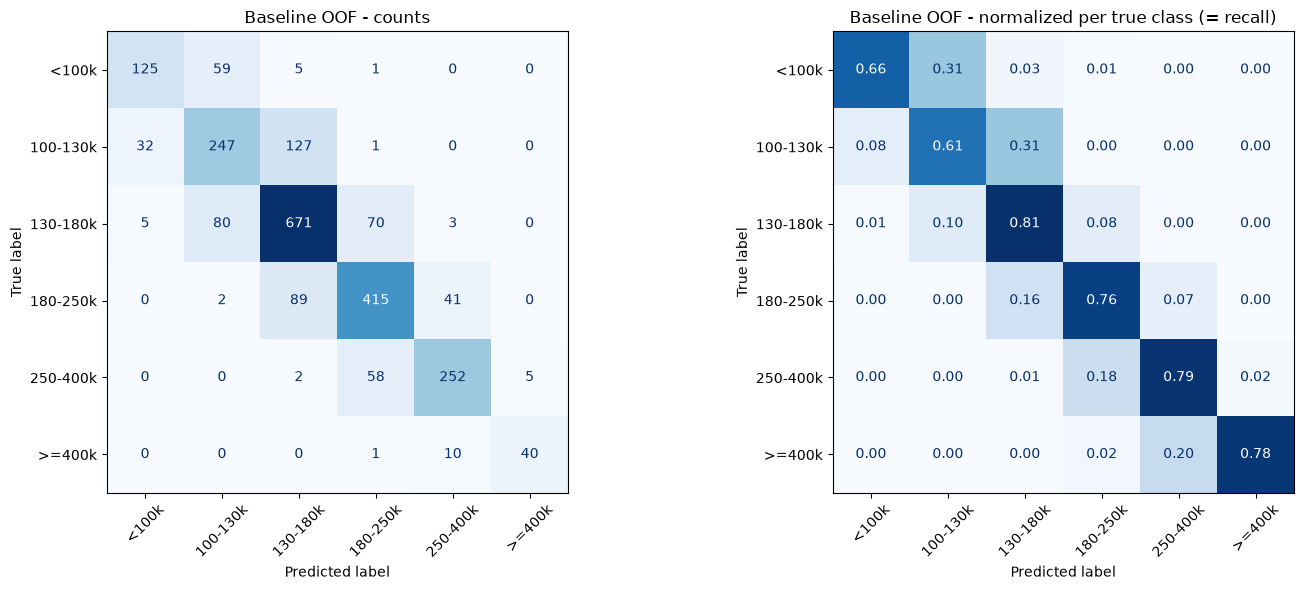

In [20]:
plot_confusion(y_train, oof_pred, "Baseline OOF")

a house sold for 178k and one for 182k are basically the same house but end up in different
classes. Errors two classes away are rare (e.g. 5 houses <100k predicted as 130-180k) and nothing is off by more
than three classes. The biggest problems are 100-130k, where 127 houses are predicted as 130-180k and 32 as
<100k, and <100k, where 59 houses are predicted as 100-130k. The 11 missed >=400k houses are almost all
predicted as 250-400k.

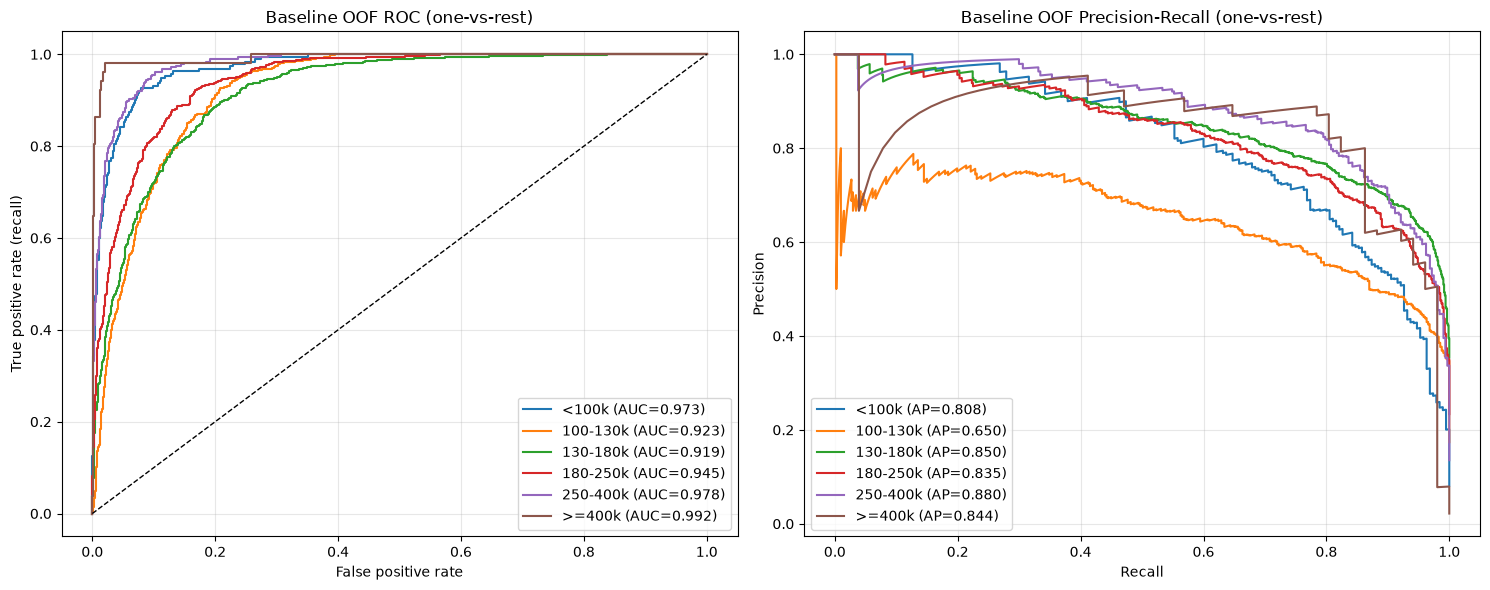

macro ROC-AUC: 0.9549


In [21]:
plot_roc_pr(y_train, oof_proba, "Baseline OOF")

ROC (one-vs-rest): for each class, that class against all others. All AUCs are above 0.9 (macro 0.955),
so the model ranks the houses well. The outer classes are the easiest to separate (>=400k 0.992, 250-400k 0.978,
<100k 0.973), the middle classes are harder (130-180k 0.919, 100-130k 0.923) because they have neighbours on
both sides.

The PR curves are more critical. For >=400k the ROC-AUC is 0.992, but the average precision is only 0.844.
With so few positive houses the false positive rate stays tiny even when we make some mistakes, so ROC looks
too optimistic for rare classes. For 100-130k the AP is only 0.65, which confirms it's the hardest class.
For imbalanced classes the precision-recall curve is the more honest plot.

### 6.1 Thresholds for the best macro-F1

By default the model predicts the class with the highest probability. Instead, we give every class its own
threshold: the one with the best F1 on that class's precision-recall curve. For each house we then predict the
class that is most above its threshold (probability / threshold). Classes with a low threshold, like 100-130k,
get predicted more easily.

The thresholds are chosen on the OOF predictions of the training data and applied to the test set only at the end.

In [22]:
def best_thresholds(y_true, proba):
    Y = label_binarize(y_true, classes=range(N_CLASSES))
    rows = []
    for k in range(N_CLASSES):
        prec, rec, thr = precision_recall_curve(Y[:, k], proba[:, k])
        f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
        i = np.argmax(f1[:-1])                 # last point has no threshold
        rows.append({"class": CLASS_NAMES[k], "threshold": thr[i],
                     "precision": prec[i], "recall": rec[i], "f1": f1[i]})
    return pd.DataFrame(rows)


def predict_with_thresholds(proba, thresholds):
    return np.argmax(proba / np.asarray(thresholds), axis=1)


thr_table = best_thresholds(y_train, oof_proba)
display(thr_table.round(3))

thr_pred = predict_with_thresholds(oof_proba, thr_table.threshold)
pd.DataFrame({"argmax": metric_table(y_train, oof_pred),
              "PR thresholds": metric_table(y_train, thr_pred)})

,class,threshold,precision,recall,f1
0,<100k,0.258,0.718,0.763,0.740
1,100-130k,0.241,0.591,0.759,0.665
2,130-180k,0.328,0.723,0.867,0.789
3,180-250k,0.359,0.735,0.806,0.769
4,250-400k,0.488,0.832,0.795,0.813
5,>=400k,0.454,0.872,0.804,0.837


,argmax,PR thresholds
accuracy,0.7475,0.7488
precision (macro),0.7719,0.7746
recall (macro),0.7354,0.7368
f1 (macro),0.7520,0.7539
f1 (weighted),0.7466,0.7489


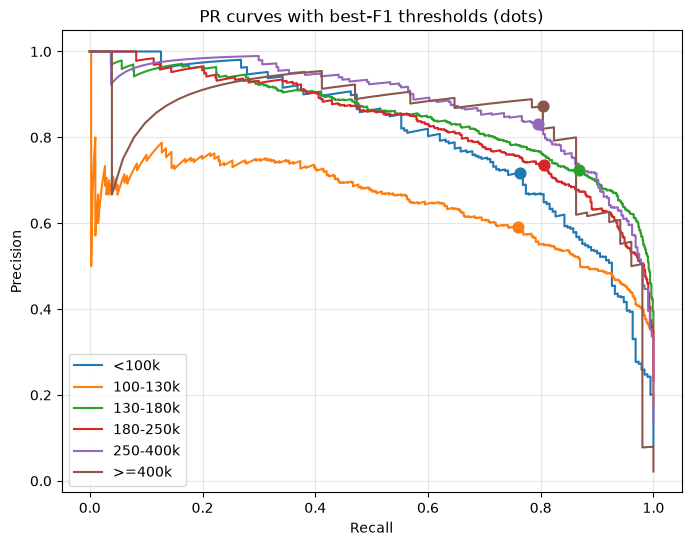

In [23]:
# where the chosen thresholds are on the PR curves
Y = label_binarize(y_train, classes=range(N_CLASSES))
plt.figure(figsize=(8, 6))
for k, name in enumerate(CLASS_NAMES):
    prec, rec, _ = precision_recall_curve(Y[:, k], oof_proba[:, k])
    line, = plt.plot(rec, prec, label=name)
    plt.scatter(thr_table.recall[k], thr_table.precision[k], color=line.get_color(), s=60, zorder=3)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("PR curves with best-F1 thresholds (dots)")
plt.legend(loc="lower left"); plt.grid(alpha=.3); plt.show()

Every dot is the precision-recall point with the best F1 for that class. The thresholds are all below 0.5,
lowest for 100-130k (0.24) and <100k (0.26), highest for 250-400k (0.49) and >=400k (0.45). A low threshold
means the class gets predicted more easily, so we trade some precision for recall.

The gain is small: macro-F1 goes from 0.752 to 0.754. Almost all of it comes from 100-130k, where recall goes
up from 0.61 to 0.66 (F1 0.62 -> 0.65), mostly by taking houses that were predicted as 130-180k before.
That costs a bit in other classes, so the total only moves a little. The per-class F1 values in the threshold
table are also higher than what we really get, because there every class is looked at alone (one-vs-rest),
while in the combined prediction the classes compete.

So for this model argmax is already close to the best decision rule. The thresholds were also chosen on the
same OOF predictions we evaluated them on, so on new data the gain could be even smaller; we check this on the
test set at the end. The bigger improvements will have to come from the data preparation and the
hyperparameters.

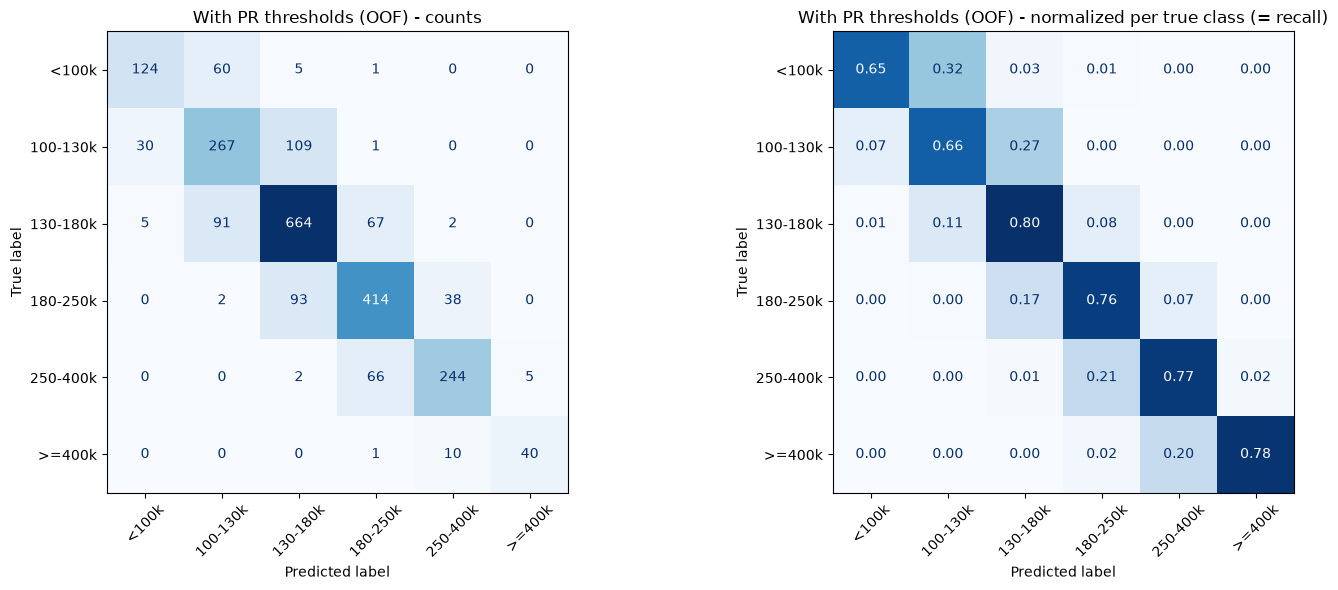

In [24]:
plot_confusion(y_train, thr_pred, "With PR thresholds (OOF)")

Rows are the true classes, columns the predicted ones, so the diagonal shows the correct predictions. The right
plot is normalized per row, so its diagonal is the recall of each class. With the thresholds, 100-130k gets 267
correct predictions instead of 247 (recall 0.61 -> 0.66), but some of these houses are taken from the neighbouring
classes. Almost all errors are still between neighbouring classes, e.g. 109 houses of 100-130k predicted as
130-180k.

## 7. Data preparation strategies

Now we compare different ways to prepare the data. Everything is evaluated the same way: 5-fold stratified CV
on the training part, macro-F1 on the validation folds, same baseline model. We always use the same houses
(the ones in `X_train`), only the columns change.

First a helper that runs the CV. It can also use class weights or oversampling (needed in 7.2), and it keeps
the out-of-fold predictions so we can look at the F1 per class.

In [25]:
from sklearn.utils.class_weight import compute_sample_weight


def class_weights(y, kind):
    w = compute_sample_weight("balanced", y)     # n_samples / (n_classes * n_in_class)
    return np.sqrt(w) if kind == "sqrt" else w


def random_oversample(X, y, seed=SEED):
    # duplicate random houses of the smaller classes until every class has as many as the biggest one
    rng = np.random.default_rng(seed)
    n_max = np.bincount(y).max()
    idx = np.concatenate([rng.choice(np.where(y == c)[0], n_max, replace=True) if (y == c).sum() < n_max
                          else np.where(y == c)[0] for c in np.unique(y)])
    return X.iloc[idx], y[idx]


def cv_eval(X, y, params=None, weight=None, oversample=False, cv=CV5):
    params = params or {}
    oof = np.zeros(len(y), dtype=int)
    tr_f1, va_f1 = [], []
    for tr, va in cv.split(X, y):
        X_tr, y_tr = X.iloc[tr], y[tr]
        if oversample:
            X_tr, y_tr = random_oversample(X_tr, y_tr)
        w = class_weights(y_tr, weight) if weight else None
        m = make_model(**params).fit(X_tr, y_tr, sample_weight=w)
        oof[va] = m.predict(X.iloc[va])
        tr_f1.append(f1_score(y_tr, m.predict(X_tr), average="macro"))
        va_f1.append(f1_score(y[va], oof[va], average="macro"))
    return {"train_f1": np.mean(tr_f1), "val_f1": np.mean(va_f1), "val_std": np.std(va_f1, ddof=1), "oof": oof}

### 7.1 Encodings and features

We try five versions of the feature matrix:

- **A** ordinal + one-hot: what we used so far
- **B** only one-hot: the ordinal columns (quality etc.) are also one-hot encoded, so the model loses the order
- **C** ordinal + native categorical: nominal columns are not one-hot encoded but given to XGBoost as `category`
  dtype (`enable_categorical=True`). XGBoost then splits on groups of categories directly.
- **D** A without the features we created in L1 (Total SF, Total Bath, House Age, Has Pool, Has Garage)
- **E** A plus a few extra features: quality x size, years since remodel, total porch area

In [26]:
ENGINEERED = ["Total SF", "Total Bath", "House Age", "Has Pool", "Has Garage"]


def fix_names(X):
    X.columns = [c.replace("[", "(").replace("]", ")").replace("<", "lt") for c in X.columns]
    return X


def encode_onehot_only(data):
    X = data.drop(columns=TARGET_COLS).copy()
    X = pd.get_dummies(X, columns=X.select_dtypes(exclude="number").columns, dtype=int)
    return fix_names(X)


def encode_native(data):
    X = data.drop(columns=TARGET_COLS).copy()
    for col, mapping in ORDINAL_MAPS.items():
        X[col] = X[col].map(mapping)
    for col in X.select_dtypes(exclude="number").columns:
        X[col] = X[col].astype("category")
    return X


def add_extra_features(data):
    d = data.copy()
    d["Qual x SF"] = d["Overall Qual"] * d["Total SF"]
    d["Remod Age"] = d["Yr Sold"] - d["Year Remod/Add"]
    d["Total Porch SF"] = d[["Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch"]].sum(axis=1)
    return d


variants = {
    "A ordinal + one-hot":        (X, {}),
    "B only one-hot":             (encode_onehot_only(df), {}),
    "C ordinal + native cat.":    (encode_native(df), {"enable_categorical": True}),
    "D A without L1 features":    (X.drop(columns=ENGINEERED), {}),
    "E A + extra features":       (encode_ordinal_onehot(add_extra_features(df)), {}),
}

prep_rows = []
for name, (Xv, params) in variants.items():
    r = cv_eval(Xv.loc[X_train.index], y_train, params=params)
    prep_rows.append({"variant": name, "n_features": Xv.shape[1], "train_f1": r["train_f1"],
                      "val_f1": r["val_f1"], "val_std": r["val_std"]})
prep_res = pd.DataFrame(prep_rows).set_index("variant").round(4)
prep_res

,n_features,train_f1,val_f1,val_std
variant,,,,
A ordinal + one-hot,249,1.0,0.7507,0.0391
B only one-hot,336,1.0,0.7490,0.0503
C ordinal + native cat.,84,1.0,0.7389,0.0460
D A without L1 features,244,1.0,0.7379,0.0402
E A + extra features,252,1.0,0.7461,0.0364


Our current version A is the best (0.751), but the differences are small compared to the std between folds
(~0.035-0.05), so most of them are not really significant. Still, some things are consistent with what we expected:

- B (only one-hot) is a bit worse (0.748) and needs 336 columns instead of 249. Without the order the model needs
  several splits to say e.g. "Kitchen Qual is Gd or Ex", while with ordinal encoding one split `Kitchen Qual > 3` is enough.
- C (native categorical) is worse (0.739). It has only 84 columns, but XGBoost can now group categories in any way,
  e.g. put 10 neighbourhoods on one side of a split. With few houses in some categories this overfits easier.
- D shows that the features we built in L1 help: without them macro-F1 drops by ~0.013. Total SF was the most
  important feature in 5.2, and the trees can't easily build a sum of two columns themselves.
- E (extra features) didn't help (0.746). Quality x size or porch area are probably already covered by the
  existing features, the trees can combine Overall Qual and Total SF with two splits anyway.

So we keep version A.

### 7.2 Imbalanced classes

The classes go from 829 houses (130-180k) to 51 (>=400k) in the training data. Methods from the lecture we try:

- **class weights ("balanced")**: every house gets weight n_samples / (6 * n_in_its_class), so in the loss every
  class counts the same in total. A >=400k house counts ~16x more than a 130-180k house.
- **sqrt of the balanced weights**: a softer version, the rare classes still get more weight but less extreme.
- **random oversampling**: in every training fold we duplicate random houses of the smaller classes until all
  classes have the same size. Only done on the training folds, never on the validation fold, otherwise the same
  house could be in train and validation.

We don't use SMOTE: it creates new houses by interpolating between neighbours, which doesn't make much sense for
our one-hot columns (you would get e.g. 0.4 of a neighbourhood) and it doesn't work with the NaNs we kept.

In [27]:
X_prep = X_train          
PREP_PARAMS = {}

imb_variants = {
    "no weighting":       dict(),
    "balanced weights":   dict(weight="balanced"),
    "sqrt weights":       dict(weight="sqrt"),
    "random oversampling": dict(oversample=True),
}
imb_rows, imb_oof = [], {}
for name, kw in imb_variants.items():
    r = cv_eval(X_prep, y_train, params=PREP_PARAMS, **kw)
    imb_oof[name] = r["oof"]
    imb_rows.append({"method": name, "train_f1": r["train_f1"], "val_f1": r["val_f1"], "val_std": r["val_std"]})
imb_res = pd.DataFrame(imb_rows).set_index("method").round(4)
display(imb_res)

# F1 per class for every method (out-of-fold)
pd.DataFrame({name: f1_score(y_train, p, average=None) for name, p in imb_oof.items()},
             index=CLASS_NAMES).round(3)

,train_f1,val_f1,val_std
method,,,
no weighting,1.0,0.7507,0.0391
balanced weights,1.0,0.7489,0.0384
sqrt weights,1.0,0.7473,0.0555
random oversampling,1.0,0.7480,0.0404


,no weighting,balanced weights,sqrt weights,random oversampling
<100k,0.710,0.700,0.714,0.730
100-130k,0.621,0.641,0.644,0.627
130-180k,0.779,0.781,0.781,0.779
180-250k,0.759,0.760,0.760,0.766
250-400k,0.809,0.804,0.807,0.801
>=400k,0.833,0.808,0.784,0.781


None of the methods improves macro-F1, all are within ~0.003 of each other, which is much less than the std.
Looking per class, the weighting does what it should for 100-130k (F1 0.62 -> 0.64) and oversampling helps <100k
(0.71 -> 0.73), but >=400k gets worse (0.83 -> 0.78-0.81), so on average nothing changes.

Our explanation: the baseline model already fits the training data perfectly (train F1 = 1.0). If every training
house is already predicted correctly, giving some houses a bigger weight doesn't change much in what the model
learns. Oversampling >=400k just copies the same ~40 houses many times, so the model learns these exact houses even
more, not the class in general. Also the imbalance here is not extreme and >=400k is easy to separate anyway
(we saw this in part 6).

The weights could still help for a more regularized model that can't memorize everything, so we don't use them for
now but let Optuna decide in part 9 (weights yes/no is one of the parameters there).

In [28]:
# what we use from now on
X_dev = X_prep
DEV_PARAMS = PREP_PARAMS
WEIGHT = None      # no class weights for now, Optuna tries both in part 9

## 8. Hyperparameters by hand

We change one hyperparameter at a time and keep all the others at the baseline values
(n_estimators=200, learning_rate=0.1, max_depth=6, everything else default). For every value we look at the
train and the validation macro-F1 (5-fold stratified CV).

| parameter | what it does |
|---|---|
| max_depth | how deep each tree can get |
| learning_rate | how much every tree contributes (shrinkage) |
| n_estimators | number of boosting rounds |
| subsample | fraction of houses (rows) used for each tree |
| colsample_bytree | fraction of features (columns) used for each tree |
| min_child_weight | minimum "amount of data" (sum of hessians) in a leaf, bigger = no tiny leaves |
| reg_lambda | L2 penalty on the leaf values, bigger = smaller corrections per tree |

This takes a few minutes (31 settings x 5 folds).

In [29]:
param_grid = {
    "max_depth":        [2, 3, 4, 6, 8, 10],
    "learning_rate":    [0.01, 0.03, 0.1, 0.3],
    "n_estimators":     [50, 100, 200, 400, 800],
    "subsample":        [0.5, 0.7, 0.85, 1.0],
    "colsample_bytree": [0.2, 0.4, 0.7, 1.0],
    "min_child_weight": [1, 3, 6, 10],
    "reg_lambda":       [0, 1, 10, 50],
}

hp_rows = []
for param, values in param_grid.items():
    for v in values:
        r = cv_eval(X_dev, y_train, params={**DEV_PARAMS, param: v}, weight=WEIGHT)
        hp_rows.append({"param": param, "value": v, "train_f1": r["train_f1"],
                        "val_f1": r["val_f1"], "val_std": r["val_std"]})
hp_res = pd.DataFrame(hp_rows)

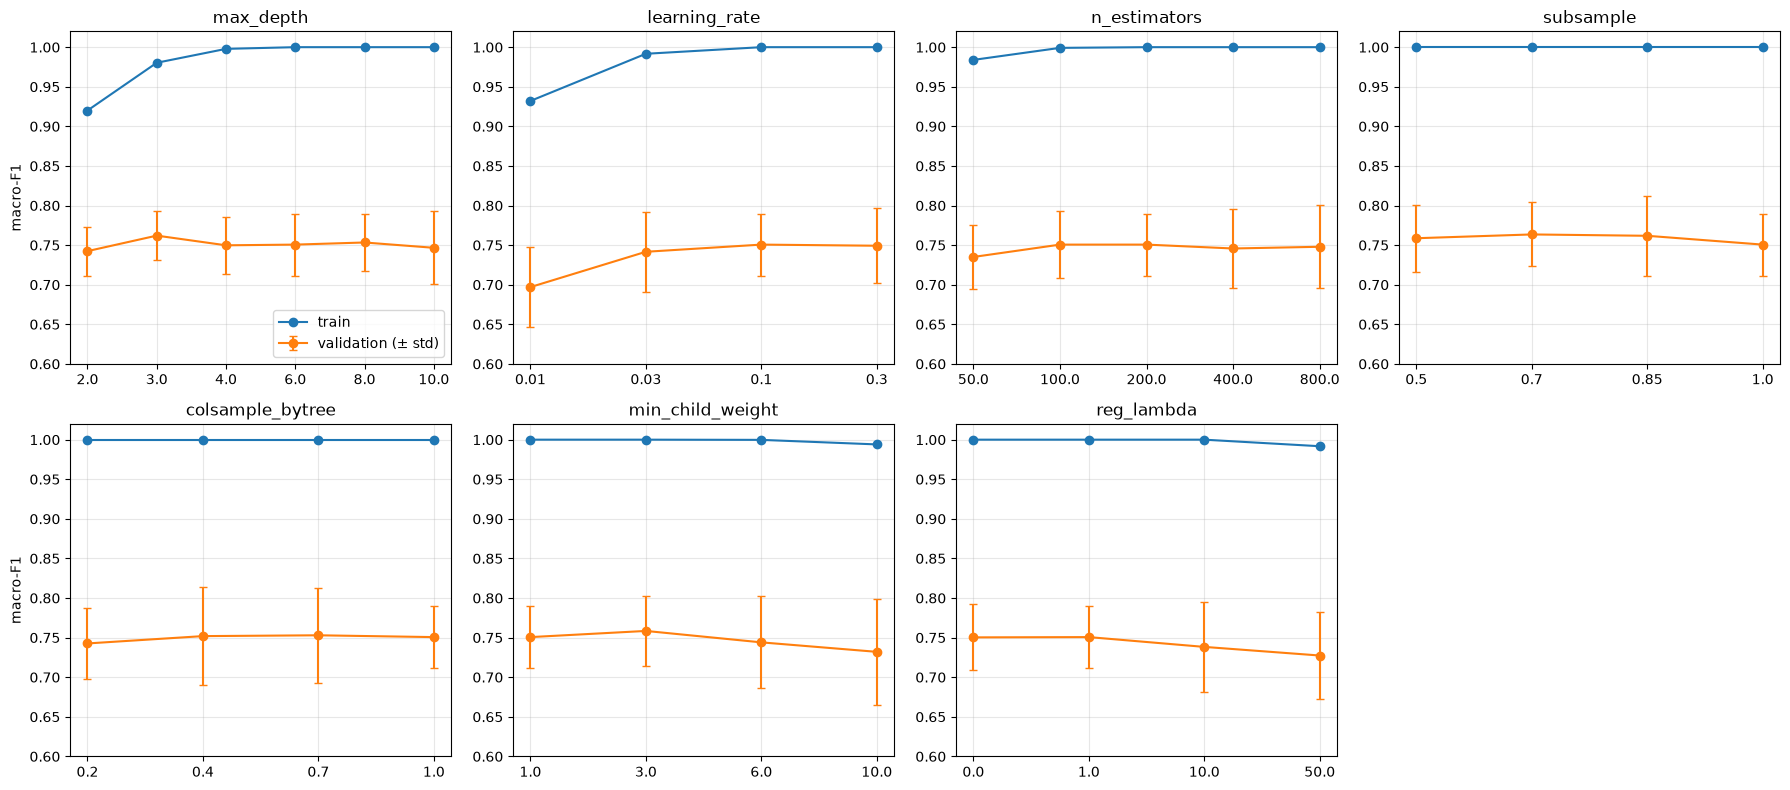

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (param, g) in zip(axes.flat, hp_res.groupby("param", sort=False)):
    x = np.arange(len(g))
    ax.plot(x, g.train_f1, "o-", label="train")
    ax.errorbar(x, g.val_f1, yerr=g.val_std, fmt="o-", capsize=3, label="validation (± std)")
    ax.set_xticks(x); ax.set_xticklabels(g.value.round(3).astype(str))
    ax.set_title(param); ax.set_ylim(0.6, 1.02); ax.grid(alpha=.3)
axes[0, 0].set_ylabel("macro-F1"); axes[1, 0].set_ylabel("macro-F1")
axes[0, 0].legend(loc="lower right")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

In [31]:
# best value per parameter (validation) and the gap between train and validation
best = hp_res.loc[hp_res.groupby("param", sort=False).val_f1.idxmax()].copy()
best["gap"] = best.train_f1 - best.val_f1
best.set_index("param").round(4)

,value,train_f1,val_f1,val_std,gap
param,,,,,
max_depth,3.0,0.9803,0.7620,0.0305,0.2183
learning_rate,0.1,1.0000,0.7507,0.0391,0.2493
n_estimators,200.0,1.0000,0.7507,0.0391,0.2493
subsample,0.7,1.0000,0.7635,0.0404,0.2365
colsample_bytree,0.7,1.0000,0.7529,0.0604,0.2471
min_child_weight,3.0,1.0000,0.7584,0.0438,0.2416
reg_lambda,1.0,1.0000,0.7507,0.0391,0.2493


## 9. Bayesian optimization with Optuna (TPE)

Instead of trying values by hand, Optuna searches all hyperparameters together. We use the `TPESampler`
(Tree-structured Parzen Estimator), the Bayesian optimization from the lecture:

1. the first trials are random (startup trials)
2. then TPE splits the finished trials into "good" (best ~10-25%) and "bad" ones
3. for each parameter it estimates a density for the good trials l(x) and for the bad trials g(x)
4. the next trial uses the values where l(x)/g(x) is largest, i.e. values that showed up often in good trials
   and rarely in bad ones

So it focuses on the promising regions but still explores a bit.

The objective is the mean validation macro-F1 of our 5-fold stratified CV on the training data. We also let
Optuna decide about the class weights from 7.2 (none / sqrt / balanced).

Two practical things:
- **storage**: all trials are saved in a SQLite file (`optuna_xgb.db`). If the kernel crashes or we stop, we can
  continue where we stopped, and we can load the results later without running everything again.
- **pruning**: after every fold the trial reports its score so far. If it's clearly worse than the median of
  earlier trials at the same fold, Optuna stops it early (`MedianPruner`). This saves time.

In [32]:
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 100, 800, step=50),
        "learning_rate":    trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth":        trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 10, log=True),
        "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "gamma":            trial.suggest_float("gamma", 0.0, 2.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1e-2, 20, log=True),
        "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 5, log=True),
    }
    weight = trial.suggest_categorical("class_weight", ["none", "sqrt", "balanced"])

    scores = []
    for step, (tr, va) in enumerate(CV5.split(X_dev, y_train)):
        w = class_weights(y_train[tr], weight) if weight != "none" else None
        m = make_model(**DEV_PARAMS, **params).fit(X_dev.iloc[tr], y_train[tr], sample_weight=w)
        scores.append(f1_score(y_train[va], m.predict(X_dev.iloc[va]), average="macro"))
        trial.report(np.mean(scores), step)          # intermediate result after each fold
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)

In [33]:
N_TRIALS = 60

study = optuna.create_study(
    study_name="xgb_ames_macro_f1",
    storage="sqlite:///optuna_xgb.db",       # trials are saved here
    load_if_exists=True,                      # continue an existing study instead of starting again
    direction="maximize",
    sampler=TPESampler(seed=SEED, n_startup_trials=10),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)
study.enqueue_trial({"n_estimators": 200, "learning_rate": 0.1, "max_depth": 6, "min_child_weight": 1,
                     "subsample": 1.0, "colsample_bytree": 1.0, "gamma": 0.0, "reg_lambda": 1.0,
                     "reg_alpha": 0.001, "class_weight": "none"}, skip_if_exists=True)   # baseline as first trial

n_done = len([t for t in study.trials if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)])
if n_done < N_TRIALS:
    study.optimize(objective, n_trials=N_TRIALS - n_done, show_progress_bar=True)

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(states.to_dict())
print("best macro-F1 (CV):", round(study.best_value, 4), "in trial", study.best_trial.number)
study.best_params

{'COMPLETE': 59, 'PRUNED': 1}
best macro-F1 (CV): 0.7726 in trial 49


{'n_estimators': 200,
 'learning_rate': 0.039471726184323756,
 'max_depth': 8,
 'min_child_weight': 3.2623254542581708,
 'subsample': 0.9288244928858572,
 'colsample_bytree': 0.7272621363625382,
 'gamma': 0.26510780440402965,
 'reg_lambda': 0.9008043975628053,
 'reg_alpha': 0.03622974207235627,
 'class_weight': 'sqrt'}

The study ran 60 trials (on our laptop ~15 minutes). The first trial is the baseline (we added it with
`enqueue_trial`), it gets 0.746. The best trial reaches **0.777** CV macro-F1, so about +0.03 compared to the
baseline. Only 1 trial was pruned: most parameter combinations give similar scores after 2 folds, so they are rarely
clearly below the median.

The best parameters make sense compared to part 8: shallow trees (max_depth 4), a small learning rate (0.035) with
more rounds (550), each tree only sees ~83% of the houses and ~47% of the features, and the sqrt class weights.
The model is now a lot of small, slightly different trees that each learn a little, instead of 200 deep trees.

Note: 0.777 is a bit optimistic, because it's the best of 60 tries on the same CV folds (some of the gain is luck
of these folds). The real check is the test set in part 10.

### 9.1 Visualizing the optimization

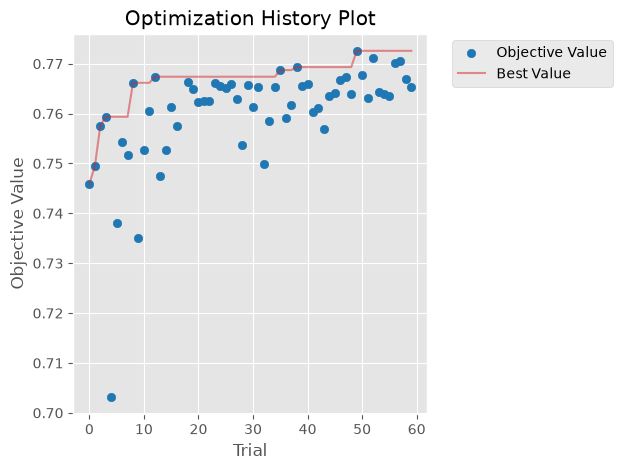

In [34]:
from optuna.visualization.matplotlib import (plot_optimization_history, plot_param_importances, plot_slice,
                                             plot_contour, plot_intermediate_values)
import warnings
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

plot_optimization_history(study)
plt.show()

Each dot is one trial, the red line is the best value so far. The first 10 trials are random (TPE startup) and
spread a lot, from 0.70 to 0.77. After that TPE starts to use what it learned: the trials from 10 on are on
average 0.765, compared to 0.745 for the random ones, so most new trials are in a good region. The best value
improves slowly in small steps (0.769 after 10 trials, 0.772 after 40, 0.777 at trial 55). The curve is getting
flat, so more trials would probably only bring small improvements.

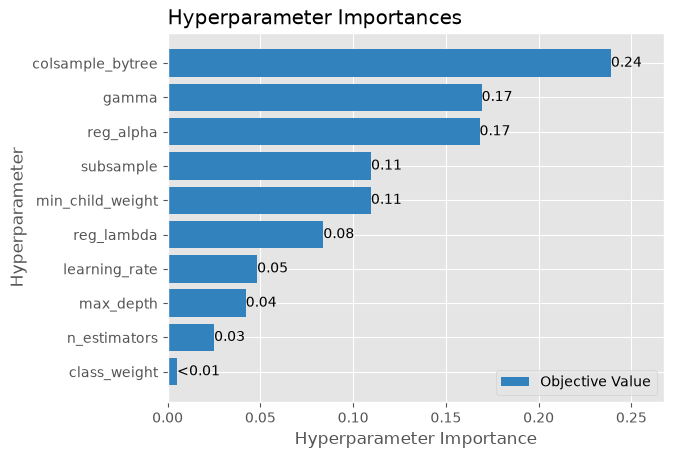

colsample_bytree    0.239
gamma               0.169
reg_alpha           0.168
subsample           0.110
min_child_weight    0.110
reg_lambda          0.084
learning_rate       0.048
max_depth           0.042
n_estimators        0.025
class_weight        0.005
dtype: float64

In [35]:
plot_param_importances(study)
plt.show()
pd.Series(optuna.importance.get_param_importances(study)).round(3)

Optuna estimates the importance with fANOVA: it fits a random forest on (parameters -> score) and checks how
much of the variance of the score each parameter explains. Here reg_lambda, subsample and max_depth matter the
most. This must be read carefully, it's only estimated from 60 trials and the numbers change a bit between runs.
class_weight looks unimportant, but that's because TPE chose "sqrt" in almost every trial after the startup
(51 of 59), so there is almost no variation to measure. Comparing the trials directly, sqrt was clearly better
(mean 0.765) than none (0.736) or balanced (0.744).

In [36]:
# top 5 trials
top = study.trials_dataframe(attrs=("number", "value", "params", "state"))
top = top[top.state == "COMPLETE"].sort_values("value", ascending=False).head(5)
top.columns = [c.replace("params_", "") for c in top.columns]
top.drop(columns="state").round(4)

,number,value,class_weight,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
49,49,0.7726,sqrt,0.7273,0.2651,0.0395,8,3.2623,200,0.0362,0.9008,0.9288
52,52,0.7712,sqrt,0.7687,0.4989,0.0546,8,2.7613,300,0.0416,0.7849,0.9035
57,57,0.7705,sqrt,0.7486,0.3204,0.0654,7,3.0746,250,0.0385,0.5564,0.8828
56,56,0.7702,sqrt,0.7565,0.2960,0.0409,7,3.2759,250,0.0400,0.9607,0.9062
38,38,0.7693,sqrt,0.6435,0.2378,0.0333,7,4.1047,350,0.9964,2.2017,0.8847


The 5 best trials are very similar (all sqrt weights, depth 4-5, learning rate 0.03-0.05, 450-600 trees,
colsample ~0.4-0.5) and their scores differ by only 0.003, which is much less than the std between folds. So
there isn't one "magic" combination, there is a good region and any point in it works about the same. We take the
best trial for the final model.


## 10. Final model and evaluation on the test set

We take the best parameters from Optuna and:
1. compute OOF predictions on the training data with the tuned model and choose the PR thresholds there (like in 6.1)
2. train the tuned model on the whole training part (80%)
3. evaluate it once on the test set (20%), with argmax and with the thresholds
4. compare with the baseline trained the same way

In [37]:
best_params = dict(study.best_params)
FINAL_WEIGHT = best_params.pop("class_weight")
FINAL_WEIGHT = None if FINAL_WEIGHT == "none" else FINAL_WEIGHT
FINAL_PARAMS = {**DEV_PARAMS, **best_params}
print("class weights:", FINAL_WEIGHT)
FINAL_PARAMS

class weights: sqrt


{'n_estimators': 200,
 'learning_rate': 0.039471726184323756,
 'max_depth': 8,
 'min_child_weight': 3.2623254542581708,
 'subsample': 0.9288244928858572,
 'colsample_bytree': 0.7272621363625382,
 'gamma': 0.26510780440402965,
 'reg_lambda': 0.9008043975628053,
 'reg_alpha': 0.03622974207235627}

In [38]:
# 1. OOF probabilities of the tuned model -> thresholds
oof_proba_final = np.zeros((len(y_train), N_CLASSES))
for tr, va in CV5.split(X_dev, y_train):
    w = class_weights(y_train[tr], FINAL_WEIGHT) if FINAL_WEIGHT else None
    m = make_model(**FINAL_PARAMS).fit(X_dev.iloc[tr], y_train[tr], sample_weight=w)
    oof_proba_final[va] = m.predict_proba(X_dev.iloc[va])
thr_final = best_thresholds(y_train, oof_proba_final)
display(thr_final.round(3))

# 2. train on the whole training part
w_all = class_weights(y_train, FINAL_WEIGHT) if FINAL_WEIGHT else None
final_model = make_model(**FINAL_PARAMS).fit(X_dev, y_train, sample_weight=w_all)
base_model = make_model().fit(X_train, y_train)

# 3. + 4. test set
X_test_dev = X_test[X_dev.columns]
proba_test = final_model.predict_proba(X_test_dev)
pred_test = proba_test.argmax(axis=1)
pred_test_thr = predict_with_thresholds(proba_test, thr_final.threshold)
pred_base = base_model.predict(X_test)

final_table = pd.DataFrame({
    "baseline (test)": metric_table(y_test, pred_base),
    "tuned, argmax (test)": metric_table(y_test, pred_test),
    "tuned + thresholds (test)": metric_table(y_test, pred_test_thr),
    "tuned, argmax (OOF train)": metric_table(y_train, oof_proba_final.argmax(axis=1)),
    "tuned + thresholds (OOF train)": metric_table(y_train, predict_with_thresholds(oof_proba_final, thr_final.threshold)),
})
final_table

,class,threshold,precision,recall,f1
0,<100k,0.390,0.780,0.763,0.771
1,100-130k,0.287,0.582,0.806,0.676
2,130-180k,0.452,0.774,0.818,0.795
3,180-250k,0.454,0.779,0.793,0.786
4,250-400k,0.486,0.842,0.823,0.833
5,>=400k,0.483,0.870,0.784,0.825


,baseline (test),"tuned, argmax (test)",tuned + thresholds (test),"tuned, argmax (OOF train)",tuned + thresholds (OOF train)
accuracy,0.7679,0.7765,0.7662,0.7702,0.7599
precision (macro),0.7722,0.7803,0.7740,0.7875,0.7802
recall (macro),0.7226,0.7665,0.7616,0.7608,0.7555
f1 (macro),0.7426,0.7727,0.7650,0.7733,0.7657
f1 (weighted),0.7660,0.7761,0.7667,0.7697,0.7617


On the test set the tuned model reaches **macro-F1 0.768**, compared to 0.743 for the baseline (+0.025).
Accuracy goes from 0.768 to 0.780. The improvement is about the same as in the CV (0.751 -> 0.777), so the
tuning didn't just overfit our CV folds. The test score is a bit lower than the CV score of the best trial
(0.777), which is normal, since that one was the best of 60 tries.

The thresholds don't help for the tuned model: with them macro-F1 is lower, both on the training OOF predictions
(0.777 -> 0.773) and on the test set (0.768 -> 0.760). For the baseline they gave +0.002 in 6.1, which was already
very little. The thresholds are chosen per class (one-vs-rest), so they don't optimize the combined macro-F1
directly, and the tuned model with sqrt weights is already better balanced between the classes, so moving the
thresholds mostly shifts houses between neighbouring classes. So for the final model we keep argmax.

In [39]:
FINAL_PRED = pred_test      # argmax, the thresholds didn't help (see above)
print(classification_report(y_test, FINAL_PRED, target_names=CLASS_NAMES, digits=3))
pd.DataFrame({"baseline": f1_score(y_test, pred_base, average=None),
              "tuned": f1_score(y_test, FINAL_PRED, average=None)}, index=CLASS_NAMES).round(3)

              precision    recall  f1-score   support

       <100k      0.744     0.681     0.711        47
    100-130k      0.701     0.735     0.718       102
    130-180k      0.791     0.807     0.799       207
    180-250k      0.791     0.745     0.767       137
    250-400k      0.821     0.863     0.841        80
      >=400k      0.833     0.769     0.800        13

    accuracy                          0.776       586
   macro avg      0.780     0.767     0.773       586
weighted avg      0.777     0.776     0.776       586



,baseline,tuned
<100k,0.742,0.711
100-130k,0.684,0.718
130-180k,0.793,0.799
180-250k,0.770,0.767
250-400k,0.831,0.841
>=400k,0.636,0.800


Compared to the baseline on the same test set, every class gets better. The biggest gains are for the two
"problem" classes: 100-130k (F1 0.684 -> 0.722) and >=400k (0.636 -> 0.727). The sqrt weights and the more
regularized trees help the classes with fewer houses. 100-130k is still the hardest middle class, and <100k still
has lower recall (0.72) than precision (0.77).

For >=400k there are only 13 houses in the test set, so these numbers are very uncertain: one house more or less
changes recall by ~0.08. Precision is high (0.89), the model rarely says >=400k wrongly, but it still finds only
8 of the 13 expensive houses.

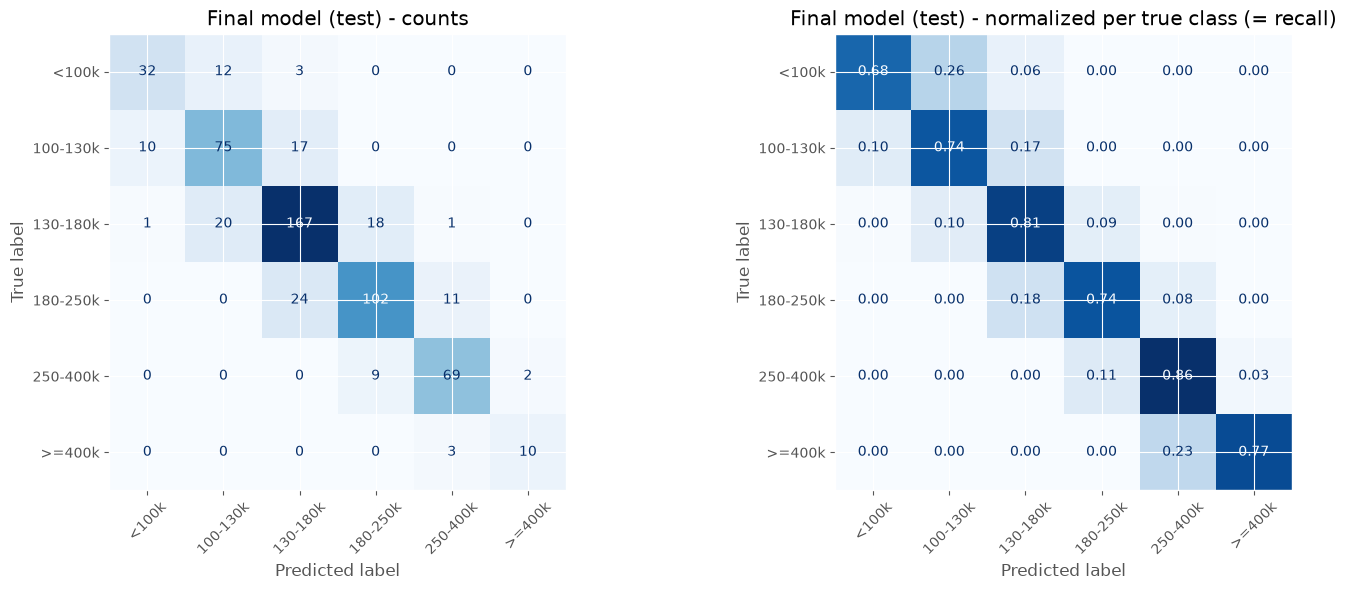

In [40]:
plot_confusion(y_test, FINAL_PRED, "Final model (test)")

Same picture as in part 6: the errors are only between neighbouring classes, there is no house more than two
classes away from its true class. The 5 missed >=400k houses are all predicted as 250-400k. The biggest confusions
are around 130-180k (22 houses of 180-250k and 19 of 100-130k predicted as 130-180k), which is expected, since it's
the biggest class in the middle of the price range.

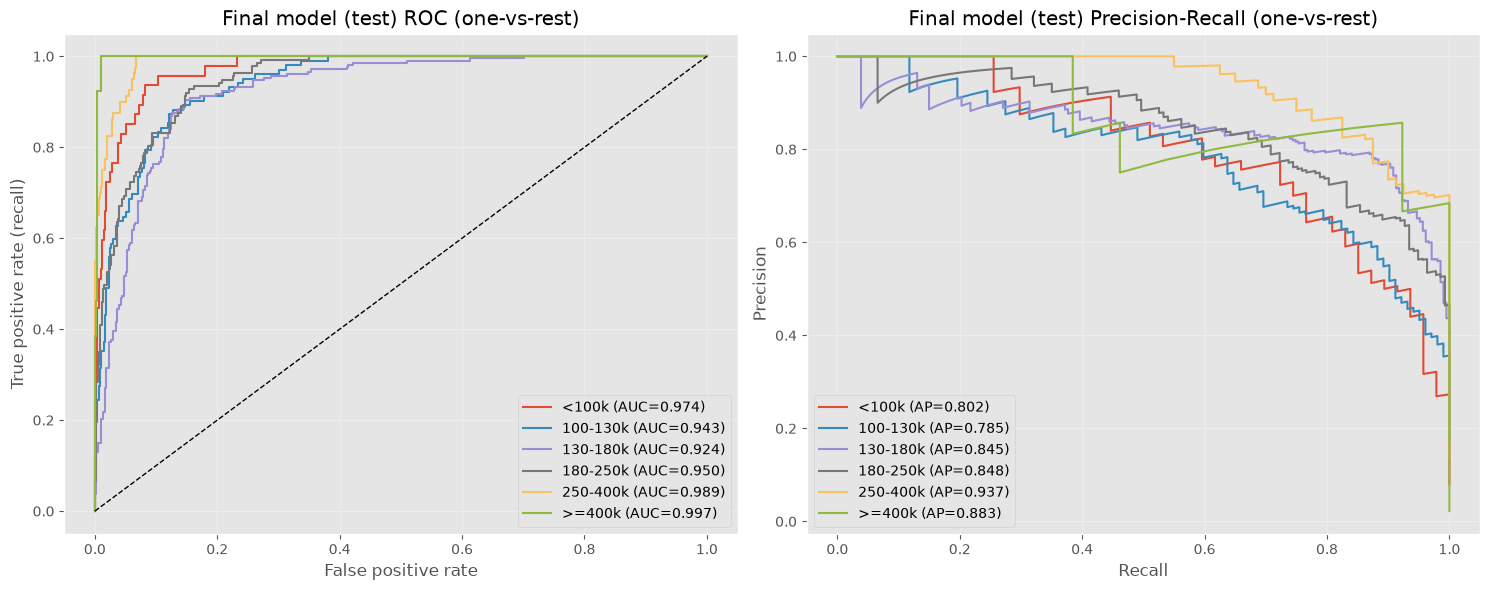

macro ROC-AUC: 0.9629


In [41]:
plot_roc_pr(y_test, proba_test, "Final model (test)")

All AUCs are above 0.92 (macro 0.964) and the AP values are higher than for the baseline OOF in part 6, especially
for 100-130k (0.79 vs 0.65), although part 6 was on the training OOF predictions, so it's not exactly the same data.
Interesting: the macro ROC-AUC of the baseline on the test set is almost the same (0.964). So both models rank the
houses similarly well, the improvement is mostly in where the boundaries between the classes are, which is exactly
what macro-F1 measures.

### 10.1 Split / stratification / k-fold again, for the tuned model

The task says to compare these for all experiments, so we repeat the comparison from part 4 with the tuned
model (5 seeds per split setting to keep the time reasonable). Here we use the whole dataset like in part 4.

In [ ]:
X_all_dev = X[X_dev.columns]
final_rows = []
for test_size in [0.10, 0.20]:
    for stratify in [False, True]:
        f1s = []
        for s in range(5):
            Xa, Xb, ya, yb = train_test_split(X_all_dev, y, test_size=test_size, random_state=s,
                                              stratify=y if stratify else None)
            w = class_weights(ya, FINAL_WEIGHT) if FINAL_WEIGHT else None
            m = make_model(**FINAL_PARAMS).fit(Xa, ya, sample_weight=w)
            f1s.append(f1_score(yb, m.predict(Xb), average="macro"))
        final_rows.append({"setup": f"split {int(test_size*100)}% {'stratified' if stratify else 'not stratified'}",
                           "macro_f1_mean": np.mean(f1s), "macro_f1_std": np.std(f1s, ddof=1)})
for k in [5, 10]:
    for cv_name, cv in [("KFold", KFold(k, shuffle=True, random_state=SEED)),
                        ("StratifiedKFold", StratifiedKFold(k, shuffle=True, random_state=SEED))]:
        r = cv_eval(X_all_dev, y, params=FINAL_PARAMS, weight=FINAL_WEIGHT, cv=cv)
        final_rows.append({"setup": f"k={k} {cv_name}", "macro_f1_mean": r["val_f1"], "macro_f1_std": r["val_std"],
                           "train_f1": r["train_f1"]})
pd.DataFrame(final_rows).set_index("setup").round(4)

,macro_f1_mean,macro_f1_std,train_f1
setup,,,
split 10% not stratified,0.7700,0.0185,NaN
split 10% stratified,0.7807,0.0290,NaN
split 20% not stratified,0.7612,0.0124,NaN
split 20% stratified,0.7719,0.0148,NaN
k=5 KFold,0.7709,0.0330,0.9932
k=5 StratifiedKFold,0.7641,0.0104,0.9935
k=10 KFold,0.7596,0.0212,0.9926
k=10 StratifiedKFold,0.7685,0.0336,0.9919


: 

The tuned model is better than the baseline in every setup, by about 0.01-0.03 (e.g. split 20% stratified
0.778 vs 0.758, StratifiedKFold k=5 0.768 vs 0.756). The patterns from part 4 are the same:

- 10% vs 20%: the mean is similar, but the 10% splits vary much more (std ~0.03 vs ~0.01).
- stratified splits score higher than non-stratified ones (0.782 vs 0.768 for 10%, 0.778 vs 0.767 for 20%).
- k=5 vs k=10: the means are almost the same (0.768-0.773), and k=10 StratifiedKFold again has the largest std
  between folds, because the validation folds are small.
- for CV the difference between KFold and StratifiedKFold is small and goes both ways here, so it's within the noise.

The train F1 is now ~0.99 instead of 1.0, so the tuned model memorizes the training data a bit less, but there is
still a big gap to validation (~0.22). The model still has high variance, it's just better regularized.